In [ ]:
import pandas as pd
import numpy as np

# So we are able to see all columns
pd.set_option('display.max_rows', 2000)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
files = os.listdir(
    "/content/drive/MyDrive/Colab Notebooks/output/statistics"
)
files

['sampled_all_systems.csv',
 'concat_flaml.csv',
 'concat_ag.csv',
 'result_monotonic_llama.csv',
 'result_monotonic_mistral.csv',
 'llama.csv',
 'mistral.csv',
 'result_equal_monotonic_ag_equal.csv',
 'result_monotonic_ag_equal.csv',
 'result_equal_monotonic_flaml_equal.csv',
 'result_monotonic_flaml_equal.csv',
 'old_concat_rf.csv',
 'old_hpo_all_systems.csv',
 'concat_rf.csv',
 'hpo_all_systems.csv',
 'result_equal_monotonic_rf_equal.csv',
 'result_monotonic_rf_equal.csv']

In [ ]:
# This is to simply obtain the dataset's type (multi or bin)
dataset_and_type = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/results_100_stratified.csv",
    sep=";"
)
dataset_and_type = dataset_and_type.loc[:, ["dataset"]]
dataset_and_type = dataset_and_type.drop_duplicates(subset=["dataset"], ignore_index=True)
dataset_and_type["pure_dataset"] = dataset_and_type["dataset"].str[:5]
dataset_and_type

,dataset,pure_dataset
0,ed_01_multi,ed_01
1,ed_02_multi,ed_02
2,ed_03_multi,ed_03
3,ed_04_multi,ed_04
4,ed_05_multi,ed_05
5,fn_01_multi,fn_01
6,fn_02_bin,fn_02
7,fn_03_multi,fn_03
8,fn_04_multi,fn_04
9,fn_05_multi,fn_05


# Random Forest with Random Search

In [ ]:
system = "rf"
system_map = {
    "rf": "Random Forest with Random Search",
    "ag": "AutoGluon",
    "flaml": "FLAML",
}

## HPO

In [ ]:
hpo = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/output/statistics/hpo_all_systems.csv",
    sep=";"
)
hpo = hpo[hpo["automl_system"] == system_map[system]]
hpo = hpo.merge(
    dataset_and_type,
    left_on="trained_dataset",
    right_on="pure_dataset",
)
hpo = hpo.rename(
    columns={
        "trained_dataset": "pure_trained_dataset",
        "dataset": "trained_dataset",
    }
)
hpo = hpo.merge(
    dataset_and_type,
    left_on="predicted_dataset",
    right_on="pure_dataset",
)
hpo = hpo.rename(
    columns={
        "predicted_dataset": "pure_predicted_dataset",
        "dataset": "predicted_dataset",
    }
)
hpo = hpo.assign(predicted_task=lambda df: df["predicted_dataset"].str[:2])
hpo["predicted_type"] = "bin"
multi_mask = hpo["predicted_dataset"].str.contains("multi")
hpo.loc[multi_mask, "predicted_type"] = "multi"

hpo["are_concat_pred_equal"] = hpo.apply(
    lambda row: row["trained_dataset"] == row["predicted_dataset"],
    axis=1
)
equal_hpo = hpo[hpo["are_concat_pred_equal"]]
diff_hpo = hpo[~(hpo["are_concat_pred_equal"])]
hpo

,pure_trained_dataset,pure_predicted_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,trained_dataset,pure_dataset_x,predicted_dataset,pure_dataset_y,predicted_task,predicted_type,are_concat_pred_equal
0,sd_01,sd_01,Random Forest with Random Search,gmm_random,100,[],[],False,0.687500,0.807292,"['hyperpartisan', 'not_hyperpartisan']","['hyperpartisan', 'not_hyperpartisan']",sd_01_bin,sd_01,sd_01_bin,sd_01,sd,bin,True
1,fn_03,fn_02,Random Forest with Random Search,gmm_random,100,"['false', 'true']",['half_true'],True,0.520833,0.000000,"['false', 'true']",['half_true'],fn_03_multi,fn_03,fn_02_bin,fn_02,fn,bin,False
2,fn_03,fn_06,Random Forest with Random Search,gmm_random,100,"['false', 'true']",['half_true'],True,0.535865,0.000000,"['false', 'true']",['half_true'],fn_03_multi,fn_03,fn_06_bin,fn_06,fn,bin,False
3,fn_03,fn_03,Random Forest with Random Search,gmm_random,100,"['pants_on_fire', 'mostly_false', 'full_flop',...",[],True,0.198683,0.198683,"['pants_on_fire', 'mostly_false', 'full_flop',...",['half_true'],fn_03_multi,fn_03,fn_03_multi,fn_03,fn,multi,True
4,fn_09,fn_10,Random Forest with Random Search,gmm_random,100,"['false', 'true', 'no_opinion']",[],True,0.516667,0.108333,"['out_of_scope', 'false', 'true', 'no_opinion']",['out_of_scope'],fn_09_multi,fn_09,fn_10_multi,fn_10,fn,multi,False
5,fn_09,fn_09,Random Forest with Random Search,gmm_random,100,"['false', 'true', 'no_opinion']",[],True,0.381391,0.381391,"['out_of_scope', 'false', 'true', 'no_opinion']",['out_of_scope'],fn_09_multi,fn_09,fn_09_multi,fn_09,fn,multi,True
6,ua_02,ua_01,Random Forest with Random Search,gmm_random,100,"['7', '5', '3', '1']",[],True,0.558380,0.558380,"['7', '5', '10', '1', '3']",['10'],ua_02_multi,ua_02,ua_01_multi,ua_01,ua,multi,False
7,ua_02,ua_03,Random Forest with Random Search,gmm_random,100,"['7', '5', '3', '1']",[],True,0.666016,0.666016,"['7', '10', '5', '1', '3']",['10'],ua_02_multi,ua_02,ua_03_multi,ua_03,ua,multi,False
8,ua_02,ua_04,Random Forest with Random Search,gmm_random,100,"['7', '5', '3', '1']",[],True,0.200040,0.200040,"['7', '10', '5', '1', '3']",['10'],ua_02_multi,ua_02,ua_04_multi,ua_04,ua,multi,False
9,ua_02,ua_05,Random Forest with Random Search,gmm_random,100,"['7', '5', '3', '1']",[],True,0.776119,0.776119,"['7', '10', '5', '1', '3']",['10'],ua_02_multi,ua_02,ua_05_multi,ua_05,ua,multi,False


## Concat

In [ ]:
automl_concat_df = pd.read_csv(
    f"/content/drive/MyDrive/Colab Notebooks/output/statistics/concat_{system}.csv",
    sep=";"
)
automl_concat_df = automl_concat_df.merge(
    dataset_and_type,
    left_on="trained_dataset",
    right_on="pure_dataset",
)
automl_concat_df = automl_concat_df.rename(
    columns={
        "trained_dataset": "pure_trained_dataset",
        "dataset": "trained_dataset",
    }
)
automl_concat_df = automl_concat_df.merge(
    dataset_and_type,
    left_on="predicted_dataset",
    right_on="pure_dataset",
)
automl_concat_df = automl_concat_df.rename(
    columns={
        "predicted_dataset": "pure_predicted_dataset",
        "dataset": "predicted_dataset",
    }
)

automl_concat_df = automl_concat_df.assign(predicted_task=lambda df: df["predicted_dataset"].str[:2])
automl_concat_df["predicted_type"] = "bin"
multi_mask = automl_concat_df["predicted_dataset"].str.contains("multi")
automl_concat_df.loc[multi_mask, "predicted_type"] = "multi"

automl_concat_df["trained_type"] = "bin"
multi_mask = automl_concat_df["trained_dataset"].str.contains("multi")
automl_concat_df.loc[multi_mask, "trained_type"] = "multi"

adapt_mask = automl_concat_df["concatenated_dataset"] == automl_concat_df["pure_predicted_dataset"]
aug_mask = automl_concat_df["pure_trained_dataset"] == automl_concat_df["pure_predicted_dataset"]

equal_concat_df = automl_concat_df.loc[adapt_mask & (~aug_mask)]
diff_concat_df = automl_concat_df.loc[(~adapt_mask) & (~aug_mask)]

automl_concat_df

,pure_trained_dataset,pure_predicted_dataset,concatenated_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,trained_dataset,pure_dataset_x,predicted_dataset,pure_dataset_y,predicted_task,predicted_type,trained_type
0,ed_03,ed_01,ed_01,Random Forest with Random Search,gmm_random,25,"['disgust', 'sadness', 'joy', 'surprise', 'fea...",['neutral'],True,0.307054,0.000000,"['disgust', 'sadness', 'joy', 'surprise', 'fea...",['neutral'],ed_03_multi,ed_03,ed_01_multi,ed_01,ed,multi,multi
1,ed_03,ed_02,ed_01,Random Forest with Random Search,gmm_random,25,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],True,0.342871,0.000000,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],ed_03_multi,ed_03,ed_02_multi,ed_02,ed,multi,multi
2,ed_03,ed_03,ed_01,Random Forest with Random Search,gmm_random,25,"['desire', 'gratitude', 'embarrassment', 'grie...",[],True,0.294867,0.294867,"['desire', 'remorse', 'confusion', 'neutral', ...",['neutral'],ed_03_multi,ed_03,ed_03_multi,ed_03,ed,multi,multi
3,ed_03,ed_01,ed_01,Random Forest with Random Search,gmm_random,50,"['disgust', 'sadness', 'joy', 'surprise', 'fea...",['neutral'],True,0.307054,0.000000,"['disgust', 'sadness', 'joy', 'surprise', 'fea...",['neutral'],ed_03_multi,ed_03,ed_01_multi,ed_01,ed,multi,multi
4,ed_03,ed_02,ed_01,Random Forest with Random Search,gmm_random,50,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],True,0.342871,0.000000,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],ed_03_multi,ed_03,ed_02_multi,ed_02,ed,multi,multi
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2035,ua_06,ua_01,ua_05,Random Forest with Random Search,gmm_random,75,"['1', '5', '3', '7']",[],True,0.558380,0.558380,"['10', '7', '5', '1', '3']",['10'],ua_06_multi,ua_06,ua_01_multi,ua_01,ua,multi,multi
2036,ua_06,ua_03,ua_05,Random Forest with Random Search,gmm_random,75,"['1', '5', '3', '7']",[],True,0.666016,0.666016,"['10', '7', '5', '1', '3']",['10'],ua_06_multi,ua_06,ua_03_multi,ua_03,ua,multi,multi
2037,ua_06,ua_04,ua_05,Random Forest with Random Search,gmm_random,75,"['1', '5', '3', '7']",[],True,0.200040,0.200040,"['10', '7', '5', '1', '3']",['10'],ua_06_multi,ua_06,ua_04_multi,ua_04,ua,multi,multi
2038,ua_06,ua_05,ua_05,Random Forest with Random Search,gmm_random,75,"['1', '5', '3', '7']",[],True,0.776119,0.776119,"['10', '7', '5', '1', '3']",['10'],ua_06_multi,ua_06,ua_05_multi,ua_05,ua,multi,multi


## 1. Evaluating Concat Equal

### 1.1 Frequency based on hold_out_f1_score

#### 1.1.1 System/Task/Percentage


In [ ]:
equal_concat_df.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean()

automl_system                     predicted_task  percentage
Random Forest with Random Search  ed              25            0.212870
                                                  50            0.221289
                                                  75            0.219186
                                  fn              25            0.289864
                                                  50            0.352183
                                                  75            0.422538
                                  hs              25            0.618249
                                                  50            0.634495
                                                  75            0.646050
                                  pc              25            0.560482
                                                  50            0.590698
                                                  75            0.596237
                                  sd              25            0.308000
                                                  50            0.333333
                                                  75            0.308000
                                  ua              25            0.505447
                                                  50            0.511016
                                                  75            0.511835
Name: hold_out_f1_score, dtype: float64

In [ ]:
diff_concat_df

,pure_trained_dataset,pure_predicted_dataset,concatenated_dataset,automl_system,method,percentage,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,trained_dataset,pure_dataset_x,predicted_dataset,pure_dataset_y,predicted_task,predicted_type,trained_type
1,ed_03,ed_02,ed_01,Random Forest with Random Search,gmm_random,25,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],True,0.342871,0.000000,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],ed_03_multi,ed_03,ed_02_multi,ed_02,ed,multi,multi
4,ed_03,ed_02,ed_01,Random Forest with Random Search,gmm_random,50,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],True,0.342871,0.000000,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],ed_03_multi,ed_03,ed_02_multi,ed_02,ed,multi,multi
7,ed_03,ed_02,ed_01,Random Forest with Random Search,gmm_random,75,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],True,0.342871,0.000000,"['sadness', 'joy', 'surprise', 'fear', 'anger'...",['neutral'],ed_03_multi,ed_03,ed_02_multi,ed_02,ed,multi,multi
9,ed_03,ed_01,ed_02,Random Forest with Random Search,gmm_random,25,"['disgust', 'sadness', 'surprise', 'fear', 'an...",['neutral'],False,0.307054,0.037344,"['disgust', 'sadness', 'joy', 'surprise', 'fea...","['joy', 'neutral']",ed_03_multi,ed_03,ed_01_multi,ed_01,ed,multi,multi
12,ed_03,ed_01,ed_02,Random Forest with Random Search,gmm_random,50,"['disgust', 'sadness', 'surprise', 'fear', 'an...",['neutral'],False,0.307054,0.257261,"['disgust', 'sadness', 'joy', 'surprise', 'fea...","['joy', 'neutral']",ed_03_multi,ed_03,ed_01_multi,ed_01,ed,multi,multi
15,ed_03,ed_01,ed_02,Random Forest with Random Search,gmm_random,75,"['disgust', 'sadness', 'surprise', 'fear', 'an...",[],True,0.307054,0.307054,"['disgust', 'sadness', 'joy', 'surprise', 'fea...",['joy'],ed_03_multi,ed_03,ed_01_multi,ed_01,ed,multi,multi
19,fn_01,fn_06,fn_02,Random Forest with Random Search,gmm_random,25,"['true', 'false']",['half_true'],True,0.535865,0.000000,"['true', 'false']",['half_true'],fn_01_multi,fn_01,fn_06_bin,fn_06,fn,bin,multi
22,fn_01,fn_06,fn_02,Random Forest with Random Search,gmm_random,50,"['true', 'false']",['half_true'],True,0.535865,0.000000,"['true', 'false']",['half_true'],fn_01_multi,fn_01,fn_06_bin,fn_06,fn,bin,multi
25,fn_01,fn_06,fn_02,Random Forest with Random Search,gmm_random,75,"['true', 'false']",['half_true'],True,0.535865,0.000000,"['true', 'false']",['half_true'],fn_01_multi,fn_01,fn_06_bin,fn_06,fn,bin,multi
27,fn_01,fn_02,fn_06,Random Forest with Random Search,gmm_random,25,"['true', 'false']",['half_true'],True,0.520833,0.000000,"['true', 'false']",['half_true'],fn_01_multi,fn_01,fn_02_bin,fn_02,fn,bin,multi


#### 1.1.2 System/Task/Percentage/Type


In [ ]:
equal_concat_df.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system                     predicted_task  percentage  predicted_type
Random Forest with Random Search  ed              25          multi             0.212870
                                                  50          multi             0.221289
                                                  75          multi             0.219186
                                  fn              25          bin               0.298497
                                                              multi             0.268281
                                                  50          bin               0.344910
                                                              multi             0.370364
                                                  75          bin               0.443407
                                                              multi             0.370364
                                  hs              25          bin               0.669722
                                                              multi             0.378042
                                                  50          bin               0.670298
                                                              multi             0.467417
                                                  75          bin               0.675988
                                                              multi             0.506344
                                  pc              25          bin               0.595474
                                                              multi             0.404962
                                                  50          bin               0.623151
                                                              multi             0.446461
                                                  75          bin               0.628134
                                                              multi             0.454473
                                  sd              25          multi             0.308000
                                                  50          multi             0.333333
                                                  75          multi             0.308000
                                  ua              25          multi             0.505447
                                                  50          multi             0.511016
                                                  75          multi             0.511835
Name: hold_out_f1_score, dtype: float64

#### 1.1.3 System/Percentage/Type

In [ ]:
equal_concat_df.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system                     percentage  predicted_type
Random Forest with Random Search  25          bin               0.584053
                                              multi             0.430499
                                  50          bin               0.604404
                                              multi             0.462265
                                  75          bin               0.621629
                                              multi             0.467917
Name: hold_out_f1_score, dtype: float64

#### 1.1.4 Task/Percentage

In [ ]:
equal_concat_df.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  percentage
ed              25            0.212870
                50            0.221289
                75            0.219186
fn              25            0.289864
                50            0.352183
                75            0.422538
hs              25            0.618249
                50            0.634495
                75            0.646050
pc              25            0.560482
                50            0.590698
                75            0.596237
sd              25            0.308000
                50            0.333333
                75            0.308000
ua              25            0.505447
                50            0.511016
                75            0.511835
Name: hold_out_f1_score, dtype: float64

#### 1.1.5 Percentage/Task/Type

In [ ]:
equal_concat_df.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type  percentage
ed              multi           25            0.212870
                                50            0.221289
                                75            0.219186
fn              bin             25            0.298497
                                50            0.344910
                                75            0.443407
                multi           25            0.268281
                                50            0.370364
                                75            0.370364
hs              bin             25            0.669722
                                50            0.670298
                                75            0.675988
                multi           25            0.378042
                                50            0.467417
                                75            0.506344
pc              bin             25            0.595474
                                50            0.623151
                                75            0.628134
                multi           25            0.404962
                                50            0.446461
                                75            0.454473
sd              multi           25            0.308000
                                50            0.333333
                                75            0.308000
ua              multi           25            0.505447
                                50            0.511016
                                75            0.511835
Name: hold_out_f1_score, dtype: float64

#### 1.1.6 Type

In [ ]:
equal_concat_df.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_type,
bin,0.603362
multi,0.453561


#### 1.1.7 Percentage/Type

In [ ]:
equal_concat_df.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_type  percentage
bin             25            0.584053
                50            0.604404
                75            0.621629
multi           25            0.430499
                50            0.462265
                75            0.467917
Name: hold_out_f1_score, dtype: float64

### 1.2 Frequency that non-sampled results (percentage=100) has the best results

In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
best_results = (
    equal_concat_df
    .groupby(["automl_system", "predicted_dataset", "method"])
    .agg({"hold_out_f1_score": "max"})
    .reset_index()
    .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
    .merge(
        equal_concat_df,
        on=["automl_system", "predicted_dataset", "method"]
    )
    .query("hold_out_f1_score == max_hold_out_f1_score")
    .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
    .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
    .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first", ignore_index=True)
)
best_results

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score
0,Random Forest with Random Search,ed_01_multi,gmm_random,25,0.000000
1,Random Forest with Random Search,ed_02_multi,gmm_random,50,0.442578
2,Random Forest with Random Search,fn_02_bin,gmm_random,25,0.520833
3,Random Forest with Random Search,fn_05_multi,gmm_random,25,0.333946
4,Random Forest with Random Search,fn_06_bin,gmm_random,25,0.535865
5,Random Forest with Random Search,fn_07_multi,gmm_random,25,0.369318
6,Random Forest with Random Search,fn_09_multi,gmm_random,25,0.261526
7,Random Forest with Random Search,fn_10_multi,gmm_random,50,0.516667
8,Random Forest with Random Search,hs_01_bin,gmm_random,25,0.716003
9,Random Forest with Random Search,hs_02_multi,gmm_random,75,0.774268


In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
percentages = [25, 50, 75, 100]
monotonic_analysis = pd.DataFrame()

for i in range(len(percentages) - 1):
    right_slice = min(i + 2, len(percentages))
    eval_percentages = percentages[i:right_slice]
    print(f"{eval_percentages=}")
    best_results = (
        equal_concat_df
        .query("percentage.isin(@eval_percentages)")
        .groupby(["automl_system", "predicted_dataset", "method"])
        .agg({"hold_out_f1_score": "max"})
        .reset_index()
        .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
        .merge(
            equal_concat_df,
            on=["automl_system", "predicted_dataset", "method"]
        )
        .query("hold_out_f1_score == max_hold_out_f1_score")
        .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
        .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
        .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first")
    )
    curr_eval_percentage = eval_percentages[0]
    non_monotonic_mask = best_results["percentage"] == curr_eval_percentage

    best_results["monotonic"] = True
    best_results.loc[non_monotonic_mask, "monotonic"] = False

    monotonic_analysis = pd.concat(
        [
            monotonic_analysis,
            best_results
        ],
        axis=0
    )

monotonic_analysis

eval_percentages=[25, 50]
eval_percentages=[50, 75]
eval_percentages=[75, 100]


,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,Random Forest with Random Search,ed_01_multi,gmm_random,25,0.000000,False
4,Random Forest with Random Search,ed_02_multi,gmm_random,50,0.442578,True
12,Random Forest with Random Search,fn_02_bin,gmm_random,25,0.520833,False
21,Random Forest with Random Search,fn_05_multi,gmm_random,25,0.333946,False
27,Random Forest with Random Search,fn_06_bin,gmm_random,25,0.535865,False
39,Random Forest with Random Search,fn_07_multi,gmm_random,25,0.369318,False
42,Random Forest with Random Search,fn_09_multi,gmm_random,25,0.261526,False
46,Random Forest with Random Search,fn_10_multi,gmm_random,50,0.516667,True
48,Random Forest with Random Search,hs_01_bin,gmm_random,25,0.716003,False
57,Random Forest with Random Search,hs_02_multi,gmm_random,25,0.773053,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,Random Forest with Random Search,ed_01_multi,gmm_random,25,0.000000,False
1,Random Forest with Random Search,fn_02_bin,gmm_random,25,0.520833,False
2,Random Forest with Random Search,fn_05_multi,gmm_random,25,0.333946,False
3,Random Forest with Random Search,fn_06_bin,gmm_random,25,0.535865,False
4,Random Forest with Random Search,fn_07_multi,gmm_random,25,0.369318,False
5,Random Forest with Random Search,fn_09_multi,gmm_random,25,0.261526,False
6,Random Forest with Random Search,hs_01_bin,gmm_random,25,0.716003,False
7,Random Forest with Random Search,hs_02_multi,gmm_random,25,0.773053,False
8,Random Forest with Random Search,hs_04_bin,gmm_random,25,0.906004,False
9,Random Forest with Random Search,hs_06_bin,gmm_random,25,0.577408,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,Random Forest with Random Search,ed_01_multi,gmm_random,25,0.000000,False
1,Random Forest with Random Search,fn_02_bin,gmm_random,25,0.520833,False
2,Random Forest with Random Search,fn_05_multi,gmm_random,25,0.333946,False
3,Random Forest with Random Search,fn_06_bin,gmm_random,25,0.535865,False
4,Random Forest with Random Search,fn_07_multi,gmm_random,25,0.369318,False
5,Random Forest with Random Search,fn_09_multi,gmm_random,25,0.261526,False
6,Random Forest with Random Search,hs_01_bin,gmm_random,25,0.716003,False
7,Random Forest with Random Search,hs_02_multi,gmm_random,25,0.773053,False
8,Random Forest with Random Search,hs_04_bin,gmm_random,25,0.906004,False
9,Random Forest with Random Search,hs_06_bin,gmm_random,25,0.577408,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system", "method"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,Random Forest with Random Search,ed_01_multi,gmm_random,25,0.000000,False
1,Random Forest with Random Search,fn_02_bin,gmm_random,25,0.520833,False
2,Random Forest with Random Search,fn_05_multi,gmm_random,25,0.333946,False
3,Random Forest with Random Search,fn_06_bin,gmm_random,25,0.535865,False
4,Random Forest with Random Search,fn_07_multi,gmm_random,25,0.369318,False
5,Random Forest with Random Search,fn_09_multi,gmm_random,25,0.261526,False
6,Random Forest with Random Search,hs_01_bin,gmm_random,25,0.716003,False
7,Random Forest with Random Search,hs_02_multi,gmm_random,25,0.773053,False
8,Random Forest with Random Search,hs_04_bin,gmm_random,25,0.906004,False
9,Random Forest with Random Search,hs_06_bin,gmm_random,25,0.577408,False


### 1.3 Dataset Label Imbalance

#### Creating imbalance dataset

In [ ]:
df_stats = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/df_stats.csv",
    sep=";",
)
df_stats = df_stats.query("method == 'gmm_random'")
df_imbalance = pd.DataFrame()
for pct in ["25", "50", "75", "100"]:
    df = df_stats[["method", "dataset", f"label_imbalance_ratio_{pct}"]]
    df = df.rename(columns={f"label_imbalance_ratio_{pct}": "label_imbalance_ratio"})
    df = df.assign(percentage=int(pct))
    df_imbalance = pd.concat(
        [
            df_imbalance,
            df
        ],
        axis=0,
    )
df_imbalance = df_imbalance.sort_values(["method", "dataset"])
df_imbalance = df_imbalance.rename(columns={"dataset": "task_and_number"})
df_imbalance["interval_ratio"] = pd.cut(
    df_imbalance["label_imbalance_ratio"],
    [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
)
df_imbalance

,method,task_and_number,label_imbalance_ratio,percentage,interval_ratio
0,gmm_random,ed_01,0.109756,25,"(0.1, 0.2]"
0,gmm_random,ed_01,0.069364,50,"(0.05, 0.1]"
0,gmm_random,ed_01,0.071698,75,"(0.05, 0.1]"
0,gmm_random,ed_01,0.072423,100,"(0.05, 0.1]"
1,gmm_random,ed_02,0.094602,25,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092692,50,"(0.05, 0.1]"
1,gmm_random,ed_02,0.091817,75,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092517,100,"(0.05, 0.1]"
2,gmm_random,ed_03,0.003691,25,"(0.0, 0.05]"
2,gmm_random,ed_03,0.004213,50,"(0.0, 0.05]"


#### 1.3.1 Mean of hold_out_f1_score by interval_ratio

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)

/tmp/ipython-input-3951610294.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


,hold_out_f1_score
interval_ratio,
"(0.0, 0.05]",0.470359
"(0.05, 0.1]",0.524574
"(0.1, 0.2]",0.551701
"(0.2, 0.3]",0.543605
"(0.3, 0.5]",0.267721
"(0.5, 0.6]",NaN
"(0.6, 0.7]",0.299556
"(0.7, 0.8]",0.667725
"(0.8, 0.9]",0.503176


#### 1.3.2 Mean of hold_out_f1_score by interval_ratio and task

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)

/tmp/ipython-input-1533895566.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.217782
               fn             0.408829
               hs             0.600450
               ua             0.498345
(0.05, 0.1]    hs             0.450601
               pc             0.580055
(0.1, 0.2]     hs             0.517544
               pc             0.564309
               ua             0.540751
(0.2, 0.3]     fn             0.261526
               hs             0.906004
               pc             0.532130
(0.3, 0.5]     fn             0.226146
               hs             0.434018
(0.6, 0.7]     sd             0.299556
(0.7, 0.8]     hs             0.667725
(0.8, 0.9]     fn             0.479167
               hs             0.697027
               sd             0.333333
(0.9, 1.0]     fn             0.434905
               hs             0.724970
               pc             0.613774
               ua             0.429824

## 2. Evaluating Concat Diff

### 2.1 Frequency based on hold_out_f1_score

#### 2.1.1 System/Task/Percentage


In [ ]:
diff_concat_df.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean()

automl_system                     predicted_task  percentage
Random Forest with Random Search  ed              25            0.018672
                                                  50            0.128631
                                                  75            0.153527
                                  fn              25            0.246242
                                                  50            0.311346
                                                  75            0.434467
                                  hs              25            0.615246
                                                  50            0.617545
                                                  75            0.630682
                                  pc              25            0.435628
                                                  50            0.429226
                                                  75            0.431156
                                  ua              25            0.491226
                                                  50            0.488342
                                                  75            0.488186
Name: hold_out_f1_score, dtype: float64

#### 2.1.2 System/Task/Percentage/Type


In [ ]:
diff_concat_df.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system                     predicted_task  percentage  predicted_type
Random Forest with Random Search  ed              25          multi             0.018672
                                                  50          multi             0.128631
                                                  75          multi             0.153527
                                  fn              25          bin               0.246242
                                                  50          bin               0.311346
                                                  75          bin               0.434467
                                  hs              25          bin               0.632459
                                                              multi             0.219361
                                                  50          bin               0.635925
                                                              multi             0.194813
                                                  75          bin               0.650194
                                                              multi             0.181893
                                  pc              25          bin               0.467727
                                                              multi             0.331448
                                                  50          bin               0.462399
                                                              multi             0.321560
                                                  75          bin               0.464421
                                                              multi             0.323189
                                  ua              25          multi             0.491226
                                                  50          multi             0.488342
                                                  75          multi             0.488186
Name: hold_out_f1_score, dtype: float64

#### 2.1.3 System/Percentage/Type

In [ ]:
diff_concat_df.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system                     percentage  predicted_type
Random Forest with Random Search  25          bin               0.514686
                                              multi             0.413324
                                  50          bin               0.514174
                                              multi             0.408621
                                  75          bin               0.523549
                                              multi             0.409170
Name: hold_out_f1_score, dtype: float64

#### 2.1.4 Task/Percentage

In [ ]:
diff_concat_df.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  percentage
ed              25            0.018672
                50            0.128631
                75            0.153527
fn              25            0.246242
                50            0.311346
                75            0.434467
hs              25            0.615246
                50            0.617545
                75            0.630682
pc              25            0.435628
                50            0.429226
                75            0.431156
ua              25            0.491226
                50            0.488342
                75            0.488186
Name: hold_out_f1_score, dtype: float64

#### 2.1.5 Percentage/Task/Type

In [ ]:
diff_concat_df.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type  percentage
ed              multi           25            0.018672
                                50            0.128631
                                75            0.153527
fn              bin             25            0.246242
                                50            0.311346
                                75            0.434467
hs              bin             25            0.632459
                                50            0.635925
                                75            0.650194
                multi           25            0.219361
                                50            0.194813
                                75            0.181893
pc              bin             25            0.467727
                                50            0.462399
                                75            0.464421
                multi           25            0.331448
                                50            0.321560
                                75            0.323189
ua              multi           25            0.491226
                                50            0.488342
                                75            0.488186
Name: hold_out_f1_score, dtype: float64

#### 2.1.6 Type

In [ ]:
diff_concat_df.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_type,
bin,0.517470
multi,0.410372


#### 2.1.7 Percentage/Type

In [ ]:
diff_concat_df.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_type  percentage
bin             25            0.514686
                50            0.514174
                75            0.523549
multi           25            0.413324
                50            0.408621
                75            0.409170
Name: hold_out_f1_score, dtype: float64

### 2.2 Frequency that non-sampled results (percentage=100) has the best results

In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
best_results = (
    diff_concat_df
    .groupby(["automl_system", "predicted_dataset", "method"])
    .agg({"hold_out_f1_score": "max"})
    .reset_index()
    .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
    .merge(
        diff_concat_df,
        on=["automl_system", "predicted_dataset", "method"]
    )
    .query("hold_out_f1_score == max_hold_out_f1_score")
    .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
    .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
    .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first", ignore_index=True)
)
best_results

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score
0,Random Forest with Random Search,ed_01_multi,gmm_random,75,0.307054
1,Random Forest with Random Search,ed_02_multi,gmm_random,25,0.000000
2,Random Forest with Random Search,fn_02_bin,gmm_random,25,0.520833
3,Random Forest with Random Search,fn_06_bin,gmm_random,25,0.464135
4,Random Forest with Random Search,hs_02_multi,gmm_random,25,0.169434
5,Random Forest with Random Search,hs_03_bin,gmm_random,25,0.504202
6,Random Forest with Random Search,hs_06_bin,gmm_random,75,0.597327
7,Random Forest with Random Search,hs_08_bin,gmm_random,25,0.930996
8,Random Forest with Random Search,hs_09_bin,gmm_random,25,0.951535
9,Random Forest with Random Search,hs_10_bin,gmm_random,50,0.643333


In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
percentages = [25, 50, 75, 100]
monotonic_analysis = pd.DataFrame()

for i in range(len(percentages) - 1):
    right_slice = min(i + 2, len(percentages))
    eval_percentages = percentages[i:right_slice]
    print(f"{eval_percentages=}")
    best_results = (
        diff_concat_df
        .query("percentage.isin(@eval_percentages)")
        .groupby(["automl_system", "predicted_dataset", "method"])
        .agg({"hold_out_f1_score": "max"})
        .reset_index()
        .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
        .merge(
            diff_concat_df,
            on=["automl_system", "predicted_dataset", "method"]
        )
        .query("hold_out_f1_score == max_hold_out_f1_score")
        .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
        .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
        .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first")
    )
    curr_eval_percentage = eval_percentages[0]
    non_monotonic_mask = best_results["percentage"] == curr_eval_percentage

    best_results["monotonic"] = True
    best_results.loc[non_monotonic_mask, "monotonic"] = False

    monotonic_analysis = pd.concat(
        [
            monotonic_analysis,
            best_results
        ],
        axis=0
    )

monotonic_analysis

eval_percentages=[25, 50]
eval_percentages=[50, 75]
eval_percentages=[75, 100]


,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
1,Random Forest with Random Search,ed_01_multi,gmm_random,50,0.257261,True
3,Random Forest with Random Search,ed_02_multi,gmm_random,25,0.000000,False
12,Random Forest with Random Search,fn_02_bin,gmm_random,25,0.520833,False
24,Random Forest with Random Search,fn_06_bin,gmm_random,25,0.464135,False
30,Random Forest with Random Search,hs_02_multi,gmm_random,25,0.169434,False
78,Random Forest with Random Search,hs_03_bin,gmm_random,25,0.504202,False
88,Random Forest with Random Search,hs_06_bin,gmm_random,50,0.590772,True
129,Random Forest with Random Search,hs_08_bin,gmm_random,25,0.930996,False
177,Random Forest with Random Search,hs_09_bin,gmm_random,25,0.951535,False
232,Random Forest with Random Search,hs_10_bin,gmm_random,50,0.643333,True


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,Random Forest with Random Search,ed_02_multi,gmm_random,25,0.000000,False
1,Random Forest with Random Search,fn_02_bin,gmm_random,25,0.520833,False
2,Random Forest with Random Search,fn_06_bin,gmm_random,25,0.464135,False
3,Random Forest with Random Search,hs_02_multi,gmm_random,25,0.169434,False
4,Random Forest with Random Search,hs_03_bin,gmm_random,25,0.504202,False
5,Random Forest with Random Search,hs_08_bin,gmm_random,25,0.930996,False
6,Random Forest with Random Search,hs_09_bin,gmm_random,25,0.951535,False
7,Random Forest with Random Search,hs_13_multi,gmm_random,25,0.708010,False
8,Random Forest with Random Search,pc_01_bin,gmm_random,25,0.636750,False
9,Random Forest with Random Search,pc_02_bin,gmm_random,25,0.759207,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,Random Forest with Random Search,ed_02_multi,gmm_random,25,0.000000,False
1,Random Forest with Random Search,fn_02_bin,gmm_random,25,0.520833,False
2,Random Forest with Random Search,fn_06_bin,gmm_random,25,0.464135,False
3,Random Forest with Random Search,hs_02_multi,gmm_random,25,0.169434,False
4,Random Forest with Random Search,hs_03_bin,gmm_random,25,0.504202,False
5,Random Forest with Random Search,hs_08_bin,gmm_random,25,0.930996,False
6,Random Forest with Random Search,hs_09_bin,gmm_random,25,0.951535,False
7,Random Forest with Random Search,hs_13_multi,gmm_random,25,0.708010,False
8,Random Forest with Random Search,pc_01_bin,gmm_random,25,0.636750,False
9,Random Forest with Random Search,pc_02_bin,gmm_random,25,0.759207,False


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system", "method"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,Random Forest with Random Search,ed_02_multi,gmm_random,25,0.000000,False
1,Random Forest with Random Search,fn_02_bin,gmm_random,25,0.520833,False
2,Random Forest with Random Search,fn_06_bin,gmm_random,25,0.464135,False
3,Random Forest with Random Search,hs_02_multi,gmm_random,25,0.169434,False
4,Random Forest with Random Search,hs_03_bin,gmm_random,25,0.504202,False
5,Random Forest with Random Search,hs_08_bin,gmm_random,25,0.930996,False
6,Random Forest with Random Search,hs_09_bin,gmm_random,25,0.951535,False
7,Random Forest with Random Search,hs_13_multi,gmm_random,25,0.708010,False
8,Random Forest with Random Search,pc_01_bin,gmm_random,25,0.636750,False
9,Random Forest with Random Search,pc_02_bin,gmm_random,25,0.759207,False


### 2.3 Dataset Label Imbalance

#### Creating imbalance dataset

In [ ]:
df_stats = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/df_stats.csv",
    sep=";",
)
df_stats = df_stats.query("method == 'gmm_random'")
df_imbalance = pd.DataFrame()
for pct in ["25", "50", "75", "100"]:
    df = df_stats[["method", "dataset", f"label_imbalance_ratio_{pct}"]]
    df = df.rename(columns={f"label_imbalance_ratio_{pct}": "label_imbalance_ratio"})
    df = df.assign(percentage=int(pct))
    df_imbalance = pd.concat(
        [
            df_imbalance,
            df
        ],
        axis=0,
    )
df_imbalance = df_imbalance.sort_values(["method", "dataset"])
df_imbalance = df_imbalance.rename(columns={"dataset": "task_and_number"})
df_imbalance["interval_ratio"] = pd.cut(
    df_imbalance["label_imbalance_ratio"],
    [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
)
df_imbalance

,method,task_and_number,label_imbalance_ratio,percentage,interval_ratio
0,gmm_random,ed_01,0.109756,25,"(0.1, 0.2]"
0,gmm_random,ed_01,0.069364,50,"(0.05, 0.1]"
0,gmm_random,ed_01,0.071698,75,"(0.05, 0.1]"
0,gmm_random,ed_01,0.072423,100,"(0.05, 0.1]"
1,gmm_random,ed_02,0.094602,25,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092692,50,"(0.05, 0.1]"
1,gmm_random,ed_02,0.091817,75,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092517,100,"(0.05, 0.1]"
2,gmm_random,ed_03,0.003691,25,"(0.0, 0.05]"
2,gmm_random,ed_03,0.004213,50,"(0.0, 0.05]"


#### 2.3.1 Mean of hold_out_f1_score by interval_ratio

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)

/tmp/ipython-input-3871234073.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


,hold_out_f1_score
interval_ratio,
"(0.0, 0.05]",0.495571
"(0.05, 0.1]",0.345329
"(0.1, 0.2]",0.441443
"(0.2, 0.3]",0.346502
"(0.3, 0.5]",0.086806
"(0.5, 0.6]",NaN
"(0.6, 0.7]",NaN
"(0.7, 0.8]",0.638458
"(0.8, 0.9]",NaN


#### 2.3.2 Mean of hold_out_f1_score by interval_ratio and task

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)

/tmp/ipython-input-3687020511.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.100277
               fn             0.411978
               hs             0.600450
               ua             0.462012
(0.05, 0.1]    hs             0.198689
               pc             0.355803
(0.1, 0.2]     pc             0.405190
               ua             0.510655
(0.2, 0.3]     pc             0.346502
(0.3, 0.5]     fn             0.086806
(0.7, 0.8]     hs             0.638458
(0.9, 1.0]     hs             0.659918
               pc             0.600513
               ua             0.465251

## 3. Evaluating HPO Equal

### 3.1 Frequency based on hold_out_f1_score

#### 3.1.1 System/Task/Percentage


In [ ]:
equal_hpo.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean()

automl_system                     predicted_task  percentage
Random Forest with Random Search  ed              100           0.453899
                                  fn              100           0.439292
                                  hs              100           0.730597
                                  pc              100           0.615680
                                  sd              100           0.575020
                                  ua              100           0.499805
Name: hold_out_f1_score, dtype: float64

#### 3.1.2 System/Task/Percentage/Type


In [ ]:
equal_hpo.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system                     predicted_task  percentage  predicted_type
Random Forest with Random Search  ed              100         multi             0.453899
                                  fn              100         bin               0.493627
                                                              multi             0.425709
                                  hs              100         bin               0.732240
                                                              multi             0.726078
                                  pc              100         bin               0.655827
                                                              multi             0.565498
                                  sd              100         bin               0.807292
                                                              multi             0.497596
                                  ua              100         multi             0.499805
Name: hold_out_f1_score, dtype: float64

#### 3.1.3 System/Percentage/Type

In [ ]:
equal_hpo.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system                     percentage  predicted_type
Random Forest with Random Search  100         bin               0.690964
                                              multi             0.511103
Name: hold_out_f1_score, dtype: float64

#### 3.1.4 Task/Percentage

In [ ]:
equal_hpo.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean()

,,hold_out_f1_score
predicted_task,percentage,
ed,100,0.453899
fn,100,0.439292
hs,100,0.730597
pc,100,0.615680
sd,100,0.575020
ua,100,0.499805


#### 3.1.5 Percentage/Task/Type

In [ ]:
equal_hpo.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type  percentage
ed              multi           100           0.453899
fn              bin             100           0.493627
                multi           100           0.425709
hs              bin             100           0.732240
                multi           100           0.726078
pc              bin             100           0.655827
                multi           100           0.565498
sd              bin             100           0.807292
                multi           100           0.497596
ua              multi           100           0.499805
Name: hold_out_f1_score, dtype: float64

#### 3.1.6 Type

In [ ]:
equal_hpo.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_type,
bin,0.690964
multi,0.511103


#### 3.1.7 Percentage/Type

In [ ]:
equal_hpo.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

,,hold_out_f1_score
predicted_type,percentage,
bin,100,0.690964
multi,100,0.511103


### 3.2 Frequency that non-sampled results (percentage=100) has the best results

In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
best_results = (
    equal_hpo
    .groupby(["automl_system", "predicted_dataset", "method"])
    .agg({"hold_out_f1_score": "max"})
    .reset_index()
    .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
    .merge(
        equal_hpo,
        on=["automl_system", "predicted_dataset", "method"]
    )
    .query("hold_out_f1_score == max_hold_out_f1_score")
    .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
    .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
    .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first", ignore_index=True)
)
best_results

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score
0,Random Forest with Random Search,ed_01_multi,gmm_random,100,0.348548
1,Random Forest with Random Search,ed_02_multi,gmm_random,100,0.379427
2,Random Forest with Random Search,ed_03_multi,gmm_random,100,0.294867
3,Random Forest with Random Search,ed_04_multi,gmm_random,100,0.904984
4,Random Forest with Random Search,ed_05_multi,gmm_random,100,0.341667
5,Random Forest with Random Search,fn_01_multi,gmm_random,100,0.200623
6,Random Forest with Random Search,fn_02_bin,gmm_random,100,0.451389
7,Random Forest with Random Search,fn_03_multi,gmm_random,100,0.198683
8,Random Forest with Random Search,fn_04_multi,gmm_random,100,0.564875
9,Random Forest with Random Search,fn_05_multi,gmm_random,100,0.333946


In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
percentages = [25, 50, 75, 100]
monotonic_analysis = pd.DataFrame()

for i in range(len(percentages) - 1):
    right_slice = min(i + 2, len(percentages))
    eval_percentages = percentages[i:right_slice]
    print(f"{eval_percentages=}")
    best_results = (
        equal_hpo
        .query("percentage.isin(@eval_percentages)")
        .groupby(["automl_system", "predicted_dataset", "method"])
        .agg({"hold_out_f1_score": "max"})
        .reset_index()
        .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
        .merge(
            equal_hpo,
            on=["automl_system", "predicted_dataset", "method"]
        )
        .query("hold_out_f1_score == max_hold_out_f1_score")
        .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
        .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
        .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first")
    )
    curr_eval_percentage = eval_percentages[0]
    non_monotonic_mask = best_results["percentage"] == curr_eval_percentage

    best_results["monotonic"] = True
    best_results.loc[non_monotonic_mask, "monotonic"] = False

    monotonic_analysis = pd.concat(
        [
            monotonic_analysis,
            best_results
        ],
        axis=0
    )

monotonic_analysis

eval_percentages=[25, 50]
eval_percentages=[50, 75]
eval_percentages=[75, 100]


,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,Random Forest with Random Search,ed_01_multi,gmm_random,100,0.348548,True
1,Random Forest with Random Search,ed_02_multi,gmm_random,100,0.379427,True
2,Random Forest with Random Search,ed_03_multi,gmm_random,100,0.294867,True
3,Random Forest with Random Search,ed_04_multi,gmm_random,100,0.904984,True
4,Random Forest with Random Search,ed_05_multi,gmm_random,100,0.341667,True
5,Random Forest with Random Search,fn_01_multi,gmm_random,100,0.200623,True
6,Random Forest with Random Search,fn_02_bin,gmm_random,100,0.451389,True
7,Random Forest with Random Search,fn_03_multi,gmm_random,100,0.198683,True
8,Random Forest with Random Search,fn_04_multi,gmm_random,100,0.564875,True
9,Random Forest with Random Search,fn_05_multi,gmm_random,100,0.333946,True


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system", "method"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


### 3.3 Dataset Label Imbalance

#### Creating imbalance dataset

In [ ]:
df_stats = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/df_stats.csv",
    sep=";",
)
df_stats = df_stats.query("method == 'gmm_random'")
df_imbalance = pd.DataFrame()
for pct in ["25", "50", "75", "100"]:
    df = df_stats[["method", "dataset", f"label_imbalance_ratio_{pct}"]]
    df = df.rename(columns={f"label_imbalance_ratio_{pct}": "label_imbalance_ratio"})
    df = df.assign(percentage=int(pct))
    df_imbalance = pd.concat(
        [
            df_imbalance,
            df
        ],
        axis=0,
    )
df_imbalance = df_imbalance.sort_values(["method", "dataset"])
df_imbalance = df_imbalance.rename(columns={"dataset": "task_and_number"})
df_imbalance["interval_ratio"] = pd.cut(
    df_imbalance["label_imbalance_ratio"],
    [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
)
df_imbalance

,method,task_and_number,label_imbalance_ratio,percentage,interval_ratio
0,gmm_random,ed_01,0.109756,25,"(0.1, 0.2]"
0,gmm_random,ed_01,0.069364,50,"(0.05, 0.1]"
0,gmm_random,ed_01,0.071698,75,"(0.05, 0.1]"
0,gmm_random,ed_01,0.072423,100,"(0.05, 0.1]"
1,gmm_random,ed_02,0.094602,25,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092692,50,"(0.05, 0.1]"
1,gmm_random,ed_02,0.091817,75,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092517,100,"(0.05, 0.1]"
2,gmm_random,ed_03,0.003691,25,"(0.0, 0.05]"
2,gmm_random,ed_03,0.004213,50,"(0.0, 0.05]"


#### 3.3.1 Mean of hold_out_f1_score by interval_ratio

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)

/tmp/ipython-input-2734163324.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


,hold_out_f1_score
interval_ratio,
"(0.0, 0.05]",0.646626
"(0.05, 0.1]",0.657485
"(0.1, 0.2]",0.528594
"(0.2, 0.3]",0.478253
"(0.3, 0.5]",0.464804
"(0.5, 0.6]",NaN
"(0.6, 0.7]",0.660979
"(0.7, 0.8]",0.563704
"(0.8, 0.9]",0.610637


#### 3.3.2 Mean of hold_out_f1_score by interval_ratio and task

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)

/tmp/ipython-input-3557226802.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.599925
               fn             0.535522
               hs             0.785539
               ua             0.721068
(0.05, 0.1]    ed             0.363988
               hs             0.803942
               pc             0.658654
(0.1, 0.2]     ed             0.341667
               hs             0.906004
               pc             0.615329
               ua             0.407276
(0.2, 0.3]     fn             0.516667
               hs             0.517544
               pc             0.372681
               sd             0.506120
(0.3, 0.5]     fn             0.305320
               hs             0.704029
(0.6, 0.7]     sd             0.660979
(0.7, 0.8]     hs             0.563704
(0.8, 0.9]     fn             0.535865
               hs             0.824047
               sd             0.472000
(0.9, 1.0]     fn             0.408933
               hs             0.694526
               pc             0.655827
               ua             0.334867

## 4. Evaluating HPO Diff

### 4.1 Frequency based on hold_out_f1_score

#### 4.1.1 System/Task/Percentage

In [ ]:
diff_hpo.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean()

automl_system                     predicted_task  percentage
Random Forest with Random Search  ed              100           0.000000
                                  fn              100           0.292962
                                  hs              100           0.554375
                                  pc              100           0.396328
                                  sd              100           0.321333
                                  ua              100           0.477326
Name: hold_out_f1_score, dtype: float64

#### 4.1.2 System/Task/Percentage/Type


In [ ]:
diff_hpo.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system                     predicted_task  percentage  predicted_type
Random Forest with Random Search  ed              100         multi             0.000000
                                  fn              100         bin               0.298497
                                                              multi             0.279125
                                  hs              100         bin               0.627383
                                                              multi             0.213670
                                  pc              100         bin               0.400594
                                                              multi             0.377369
                                  sd              100         multi             0.321333
                                  ua              100         multi             0.477326
Name: hold_out_f1_score, dtype: float64

#### 4.1.3 System/Percentage/Type

In [ ]:
diff_hpo.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

automl_system                     percentage  predicted_type
Random Forest with Random Search  100         bin               0.468916
                                              multi             0.382722
Name: hold_out_f1_score, dtype: float64

#### 4.1.4 Task/Percentage

In [ ]:
diff_hpo.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean()

,,hold_out_f1_score
predicted_task,percentage,
ed,100,0.000000
fn,100,0.292962
hs,100,0.554375
pc,100,0.396328
sd,100,0.321333
ua,100,0.477326


#### 4.1.5 Percentage/Task/Type

In [ ]:
diff_hpo.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type  percentage
ed              multi           100           0.000000
fn              bin             100           0.298497
                multi           100           0.279125
hs              bin             100           0.627383
                multi           100           0.213670
pc              bin             100           0.400594
                multi           100           0.377369
sd              multi           100           0.321333
ua              multi           100           0.477326
Name: hold_out_f1_score, dtype: float64

#### 4.1.6 Type

In [ ]:
diff_hpo.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_type,
bin,0.468916
multi,0.382722


#### 4.1.7 Percentage/Type

In [ ]:
diff_hpo.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean()

,,hold_out_f1_score
predicted_type,percentage,
bin,100,0.468916
multi,100,0.382722


### 4.2 Frequency that non-sampled results (percentage=100) has the best results

In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
best_results = (
    diff_hpo
    .groupby(["automl_system", "predicted_dataset", "method"])
    .agg({"hold_out_f1_score": "max"})
    .reset_index()
    .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
    .merge(
        diff_hpo,
        on=["automl_system", "predicted_dataset", "method"]
    )
    .query("hold_out_f1_score == max_hold_out_f1_score")
    .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
    .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
    .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first", ignore_index=True)
)
best_results

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score
0,Random Forest with Random Search,ed_01_multi,gmm_random,100,0.000000
1,Random Forest with Random Search,ed_02_multi,gmm_random,100,0.000000
2,Random Forest with Random Search,fn_02_bin,gmm_random,100,0.520833
3,Random Forest with Random Search,fn_05_multi,gmm_random,100,0.377322
4,Random Forest with Random Search,fn_06_bin,gmm_random,100,0.535865
5,Random Forest with Random Search,fn_07_multi,gmm_random,100,0.369318
6,Random Forest with Random Search,fn_09_multi,gmm_random,100,0.261526
7,Random Forest with Random Search,fn_10_multi,gmm_random,100,0.108333
8,Random Forest with Random Search,hs_01_bin,gmm_random,100,0.448450
9,Random Forest with Random Search,hs_02_multi,gmm_random,100,0.169434


In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
percentages = [25, 50, 75, 100]
monotonic_analysis = pd.DataFrame()

for i in range(len(percentages) - 1):
    right_slice = min(i + 2, len(percentages))
    eval_percentages = percentages[i:right_slice]
    print(f"{eval_percentages=}")
    best_results = (
        diff_hpo
        .query("percentage.isin(@eval_percentages)")
        .groupby(["automl_system", "predicted_dataset", "method"])
        .agg({"hold_out_f1_score": "max"})
        .reset_index()
        .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
        .merge(
            diff_hpo,
            on=["automl_system", "predicted_dataset", "method"]
        )
        .query("hold_out_f1_score == max_hold_out_f1_score")
        .loc[:, ["automl_system", "predicted_dataset", "method", "percentage", "hold_out_f1_score"]]
        .sort_values(["automl_system", "predicted_dataset", "method", "percentage"])
        .drop_duplicates(["automl_system", "predicted_dataset", "method"], keep="first")
    )
    curr_eval_percentage = eval_percentages[0]
    non_monotonic_mask = best_results["percentage"] == curr_eval_percentage

    best_results["monotonic"] = True
    best_results.loc[non_monotonic_mask, "monotonic"] = False

    monotonic_analysis = pd.concat(
        [
            monotonic_analysis,
            best_results
        ],
        axis=0
    )

monotonic_analysis

eval_percentages=[25, 50]
eval_percentages=[50, 75]
eval_percentages=[75, 100]


,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic
0,Random Forest with Random Search,ed_01_multi,gmm_random,100,0.000000,True
1,Random Forest with Random Search,ed_02_multi,gmm_random,100,0.000000,True
3,Random Forest with Random Search,fn_02_bin,gmm_random,100,0.520833,True
7,Random Forest with Random Search,fn_05_multi,gmm_random,100,0.377322,True
12,Random Forest with Random Search,fn_06_bin,gmm_random,100,0.535865,True
13,Random Forest with Random Search,fn_07_multi,gmm_random,100,0.369318,True
14,Random Forest with Random Search,fn_09_multi,gmm_random,100,0.261526,True
15,Random Forest with Random Search,fn_10_multi,gmm_random,100,0.108333,True
16,Random Forest with Random Search,hs_01_bin,gmm_random,100,0.448450,True
18,Random Forest with Random Search,hs_02_multi,gmm_random,100,0.169434,True


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset", "automl_system", "method"], ignore_index=True)

,automl_system,predicted_dataset,method,percentage,hold_out_f1_score,monotonic


### 4.3 Dataset Label Imbalance

#### Creating imbalance dataset

In [ ]:
df_stats = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/df_stats.csv",
    sep=";",
)
df_stats = df_stats.query("method == 'gmm_random'")
df_imbalance = pd.DataFrame()
for pct in ["25", "50", "75", "100"]:
    df = df_stats[["method", "dataset", f"label_imbalance_ratio_{pct}"]]
    df = df.rename(columns={f"label_imbalance_ratio_{pct}": "label_imbalance_ratio"})
    df = df.assign(percentage=int(pct))
    df_imbalance = pd.concat(
        [
            df_imbalance,
            df
        ],
        axis=0,
    )
df_imbalance = df_imbalance.sort_values(["method", "dataset"])
df_imbalance = df_imbalance.rename(columns={"dataset": "task_and_number"})
df_imbalance["interval_ratio"] = pd.cut(
    df_imbalance["label_imbalance_ratio"],
    [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
)
df_imbalance

,method,task_and_number,label_imbalance_ratio,percentage,interval_ratio
0,gmm_random,ed_01,0.109756,25,"(0.1, 0.2]"
0,gmm_random,ed_01,0.069364,50,"(0.05, 0.1]"
0,gmm_random,ed_01,0.071698,75,"(0.05, 0.1]"
0,gmm_random,ed_01,0.072423,100,"(0.05, 0.1]"
1,gmm_random,ed_02,0.094602,25,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092692,50,"(0.05, 0.1]"
1,gmm_random,ed_02,0.091817,75,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092517,100,"(0.05, 0.1]"
2,gmm_random,ed_03,0.003691,25,"(0.0, 0.05]"
2,gmm_random,ed_03,0.004213,50,"(0.0, 0.05]"


#### 4.3.1 Mean of hold_out_f1_score by interval_ratio

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)

/tmp/ipython-input-2727227245.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


,hold_out_f1_score
interval_ratio,
"(0.0, 0.05]",0.419779
"(0.05, 0.1]",0.181217
"(0.1, 0.2]",0.447907
"(0.2, 0.3]",0.227762
"(0.3, 0.5]",0.182334
"(0.5, 0.6]",NaN
"(0.6, 0.7]",0.320000
"(0.7, 0.8]",0.649907
"(0.8, 0.9]",0.416761


#### 4.3.2 Mean of hold_out_f1_score by interval_ratio and task

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)

/tmp/ipython-input-2953702698.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.000000
               fn             0.328323
               hs             0.600450
               ua             0.480396
(0.05, 0.1]    hs             0.213670
               pc             0.156876
(0.1, 0.2]     hs             0.517544
               pc             0.364026
               ua             0.532883
(0.2, 0.3]     fn             0.261526
               hs             0.906004
               pc             0.126047
(0.3, 0.5]     fn             0.119413
               hs             0.434018
(0.6, 0.7]     sd             0.320000
(0.7, 0.8]     hs             0.649907
(0.8, 0.9]     fn             0.479167
               hs             0.448450
               sd             0.322667
(0.9, 1.0]     fn             0.456593
               hs             0.640928
               pc             0.609317
               ua             0.290627

In [ ]:
# Summarize insights from the equal_concat_df and diff_concat_df DataFrames based on median hold_out_f1_score.
print("\n--- Insights from equal_concat_df (Concatenated Trained == Predicted) ---")
print("Median hold_out_f1_score by System, Predicted Task, and Percentage:")
print(equal_concat_df.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Predicted Task, Percentage, and Type:")
print(equal_concat_df.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Percentage, and Type:")
print(equal_concat_df.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task and Percentage:")
print(equal_concat_df.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task, Type, and Percentage:")
print(equal_concat_df.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type:")
print(equal_concat_df.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type and Percentage:")
print(equal_concat_df.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())

print("\n--- Insights from diff_concat_df (Concatenated Trained != Predicted) ---")
print("Median hold_out_f1_score by System, Predicted Task, and Percentage:")
print(diff_concat_df.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Predicted Task, Percentage, and Type:")
print(diff_concat_df.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Percentage, and Type:")
print(diff_concat_df.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task and Percentage:")
print(diff_concat_df.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task, Type, and Percentage:")
print(diff_concat_df.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type:")
print(diff_concat_df.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type and Percentage:")
print(diff_concat_df.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())

# Summarize insights from the equal_hpo and diff_hpo DataFrames based on median hold_out_f1_score.

print("\n--- Insights from equal_hpo (HPO Trained == Predicted) ---")
print("Median hold_out_f1_score by System, Predicted Task, and Percentage:")
print(equal_hpo.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Predicted Task, Percentage, and Type:")
print(equal_hpo.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Percentage, and Type:")
print(equal_hpo.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task and Percentage:")
print(equal_hpo.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task, Type, and Percentage:")
print(equal_hpo.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type:")
print(equal_hpo.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type and Percentage:")
print(equal_hpo.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())

print("\n--- Insights from diff_hpo (HPO Trained != Predicted) ---")
print("Median hold_out_f1_score by System, Predicted Task, and Percentage:")
print(diff_hpo.groupby(["automl_system", "predicted_task", "percentage"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Predicted Task, Percentage, and Type:")
print(diff_hpo.groupby(["automl_system", "predicted_task", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by System, Percentage, and Type:")
print(diff_hpo.groupby(["automl_system", "percentage", "predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task and Percentage:")
print(diff_hpo.groupby(["predicted_task", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Task, Type, and Percentage:")
print(diff_hpo.groupby(["predicted_task", "predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type:")
print(diff_hpo.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean())
print("\nMedian hold_out_f1_score by Predicted Type and Percentage:")
print(diff_hpo.groupby(["predicted_type", "percentage",], observed=False)["hold_out_f1_score"].mean())


--- Insights from equal_concat_df (Concatenated Trained == Predicted) ---
Median hold_out_f1_score by System, Predicted Task, and Percentage:
automl_system                     predicted_task  percentage
Random Forest with Random Search  ed              25            0.212870
                                                  50            0.221289
                                                  75            0.219186
                                  fn              25            0.289864
                                                  50            0.352183
                                                  75            0.422538
                                  hs              25            0.618249
                                                  50            0.634495
                                                  75            0.646050
                                  pc              25            0.560482
                                                  50            0.

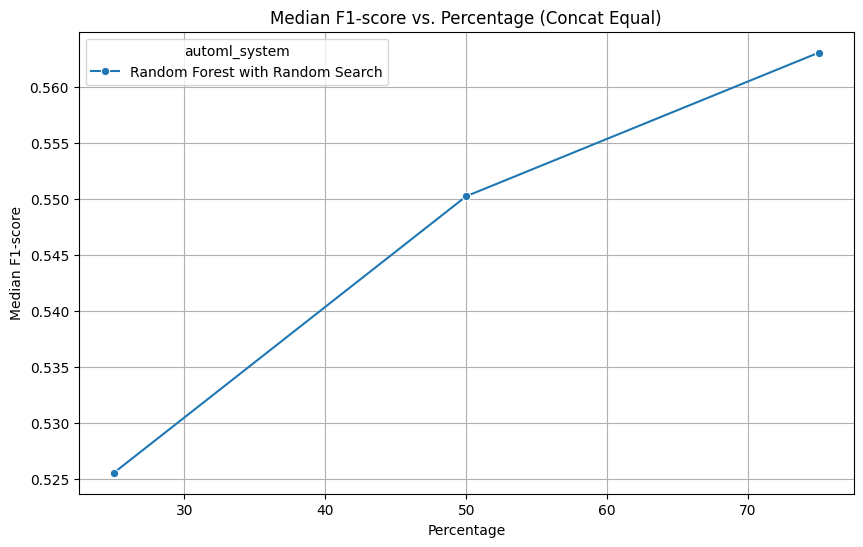

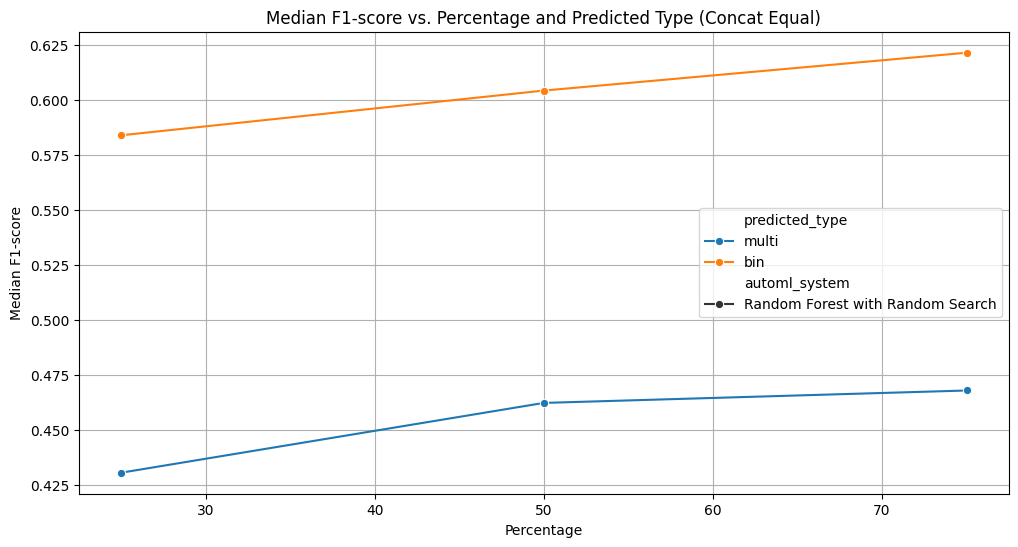

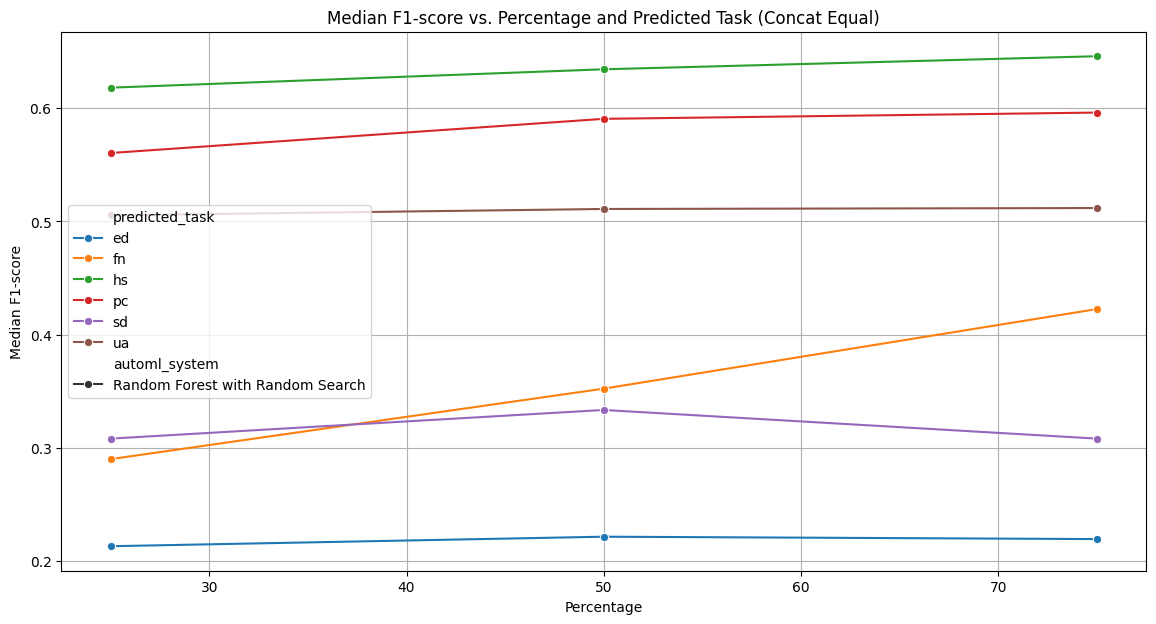

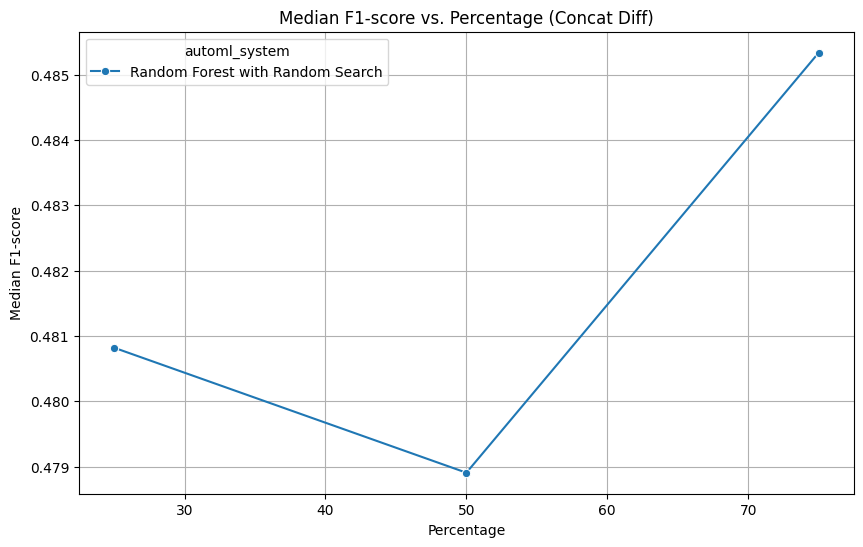

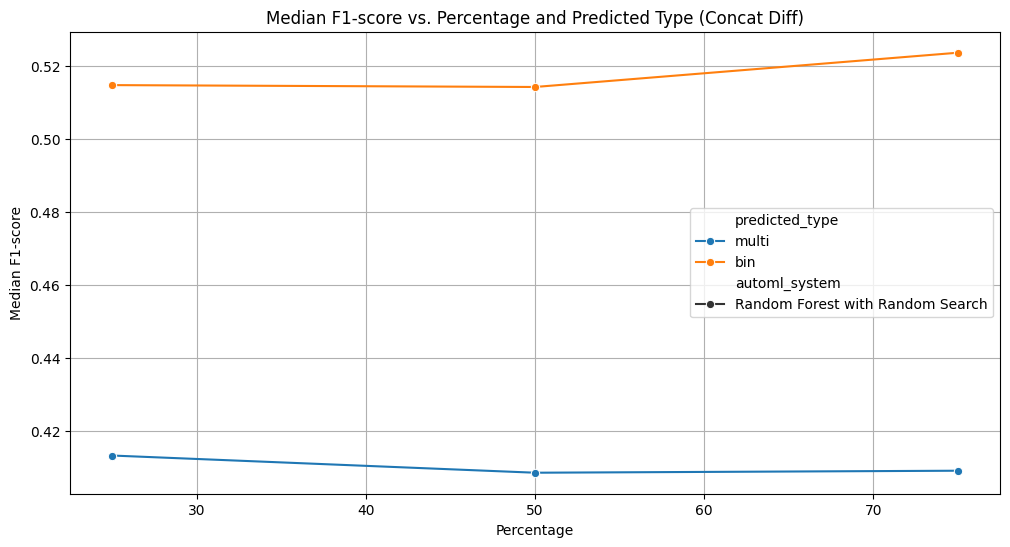

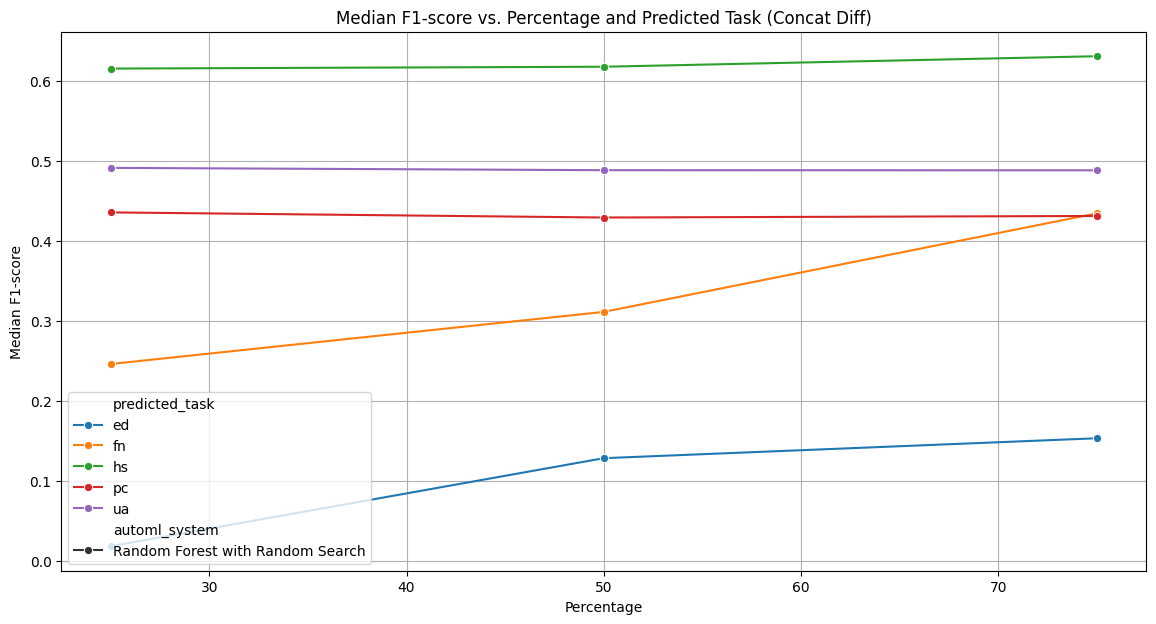

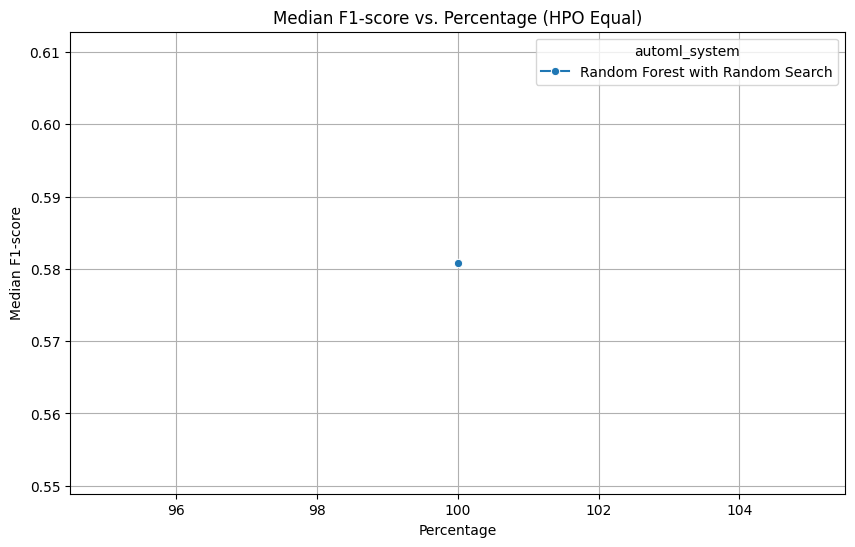

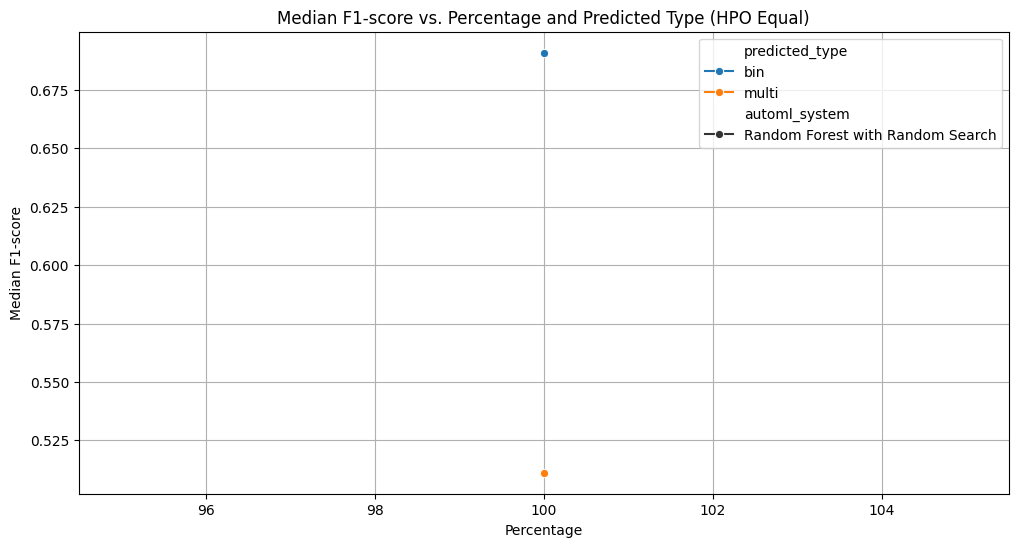

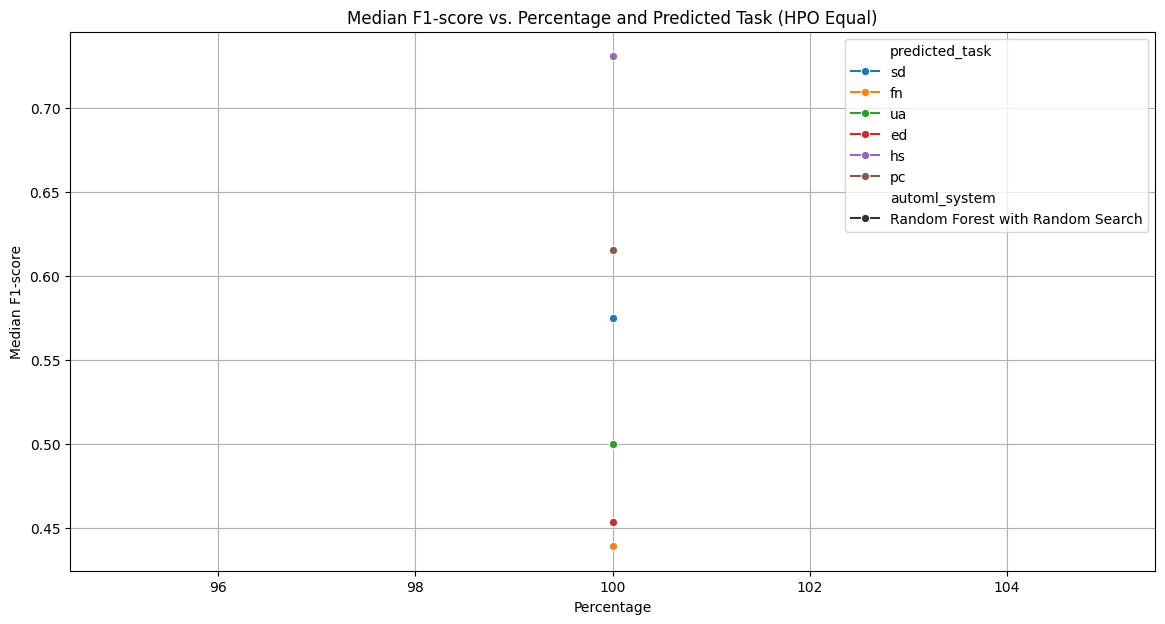

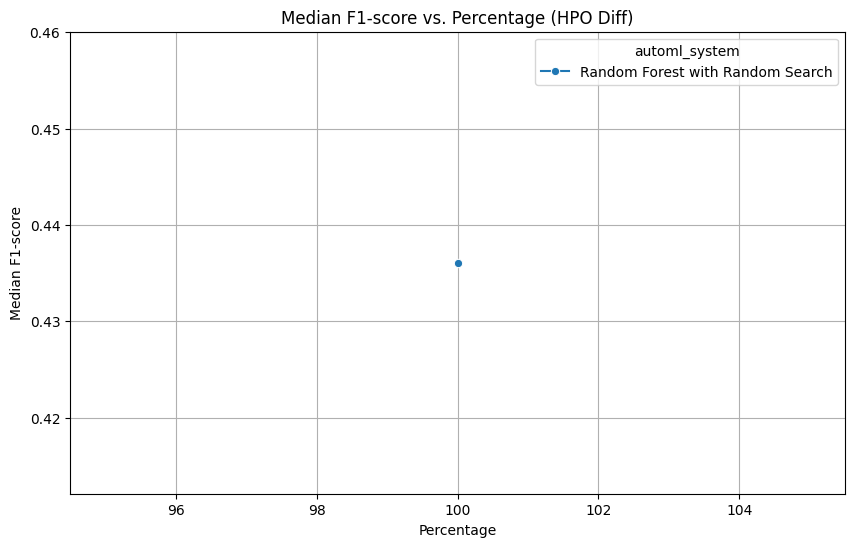

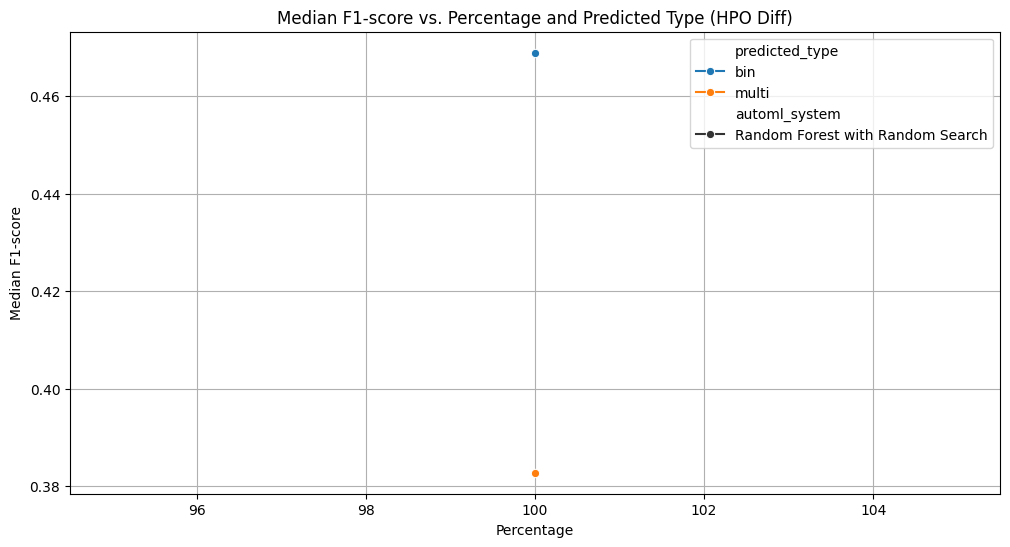

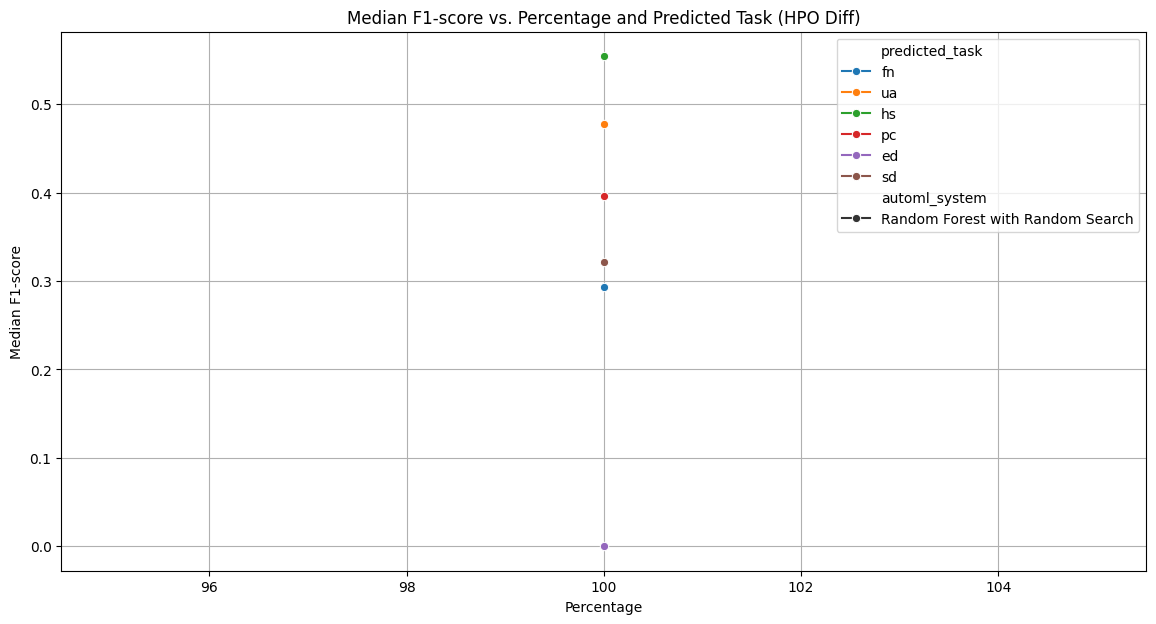


--- Monotonicity Analysis for Concat Equal ---
Datasets where a smaller percentage achieved the best result (Non-monotonic):
Empty DataFrame
Columns: [automl_system, predicted_dataset, method, percentage, hold_out_f1_score, monotonic]
Index: []

--- Monotonicity Analysis for Concat Diff ---
Datasets where a smaller percentage achieved the best result (Non-monotonic):
Empty DataFrame
Columns: [automl_system, predicted_dataset, method, percentage, hold_out_f1_score, monotonic]
Index: []

--- Monotonicity Analysis for HPO Equal ---
Datasets where a smaller percentage achieved the best result (Non-monotonic):
Empty DataFrame
Columns: [automl_system, predicted_dataset, method, percentage, hold_out_f1_score, monotonic]
Index: []

--- Monotonicity Analysis for HPO Diff ---
Datasets where a smaller percentage achieved the best result (Non-monotonic):
Empty DataFrame
Columns: [automl_system, predicted_dataset, method, percentage, hold_out_f1_score, monotonic]
Index: []

--- Label Imbalance Ins

/tmp/ipython-input-1745362849.py:257: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")
/tmp/ipython-input-1745362849.py:274: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])
/tmp/ipython-input-1745362849.py:293: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")
/tmp/ipython-input-1745362849.py:310: FutureWarning: The default of observed=Fals

hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.000000
               fn             0.328323
               hs             0.600450
               ua             0.480396
(0.05, 0.1]    hs             0.213670
               pc             0.156876
(0.1, 0.2]     hs             0.517544
               pc             0.364026
               ua             0.532883
(0.2, 0.3]     fn             0.261526
               hs             0.906004
               pc             0.126047
(0.3, 0.5]     fn             0.119413
               hs             0.434018
(0.6, 0.7]     sd             0.320000
(0.7, 0.8]     hs             0.649907
(0.8, 0.9]     fn             0.479167
               hs             0.448450
               sd             0.322667
(0.9, 1.0]     fn             0.456593
               hs             0.640928
               pc             0.609317
               ua             0.290627

In [ ]:
!pip install matplotlib seaborn
import matplotlib.pyplot as plt
import seaborn as sns

# --- Visualizing Concat Equal ---

# Median F1-score by Percentage for Concat Equal
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=equal_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="automl_system",
    marker='o',
    errorbar=None  # Hide error bars for median
)
plt.title("Median F1-score vs. Percentage (Concat Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Percentage and Predicted Type for Concat Equal
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=equal_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_type",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Type (Concat Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Predicted Task and Percentage for Concat Equal
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=equal_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_task",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Task (Concat Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()


# --- Visualizing Concat Diff ---

# Median F1-score by Percentage for Concat Diff
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=diff_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage (Concat Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Percentage and Predicted Type for Concat Diff
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=diff_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_type",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Type (Concat Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Predicted Task and Percentage for Concat Diff
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=diff_concat_df,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_task",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Task (Concat Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()


# --- Visualizing HPO Equal ---

# Median F1-score by Percentage for HPO Equal
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=equal_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage (HPO Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Percentage and Predicted Type for HPO Equal
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=equal_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_type",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Type (HPO Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Predicted Task and Percentage for HPO Equal
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=equal_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_task",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Task (HPO Equal)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()


# --- Visualizing HPO Diff ---

# Median F1-score by Percentage for HPO Diff
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=diff_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage (HPO Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Percentage and Predicted Type for HPO Diff
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=diff_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_type",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Type (HPO Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

# Median F1-score by Predicted Task and Percentage for HPO Diff
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=diff_hpo,
    x="percentage",
    y="hold_out_f1_score",
    hue="predicted_task",
    style="automl_system",
    marker='o',
    errorbar=None
)
plt.title("Median F1-score vs. Percentage and Predicted Task (HPO Diff)")
plt.xlabel("Percentage")
plt.ylabel("Median F1-score")
plt.grid(True)
plt.show()

automl_system = system_map[system]

# Insight regarding monotonicity for Concat Equal
print("\n--- Monotonicity Analysis for Concat Equal ---")
print("Datasets where a smaller percentage achieved the best result (Non-monotonic):")
non_monotonic_datasets_concat_equal = monotonic_analysis.query("~monotonic & (automl_system == @automl_system)")
print(non_monotonic_datasets_concat_equal.drop_duplicates(["predicted_dataset", "method"], ignore_index=True))

# Insight regarding monotonicity for Concat Diff
print("\n--- Monotonicity Analysis for Concat Diff ---")
print("Datasets where a smaller percentage achieved the best result (Non-monotonic):")
non_monotonic_datasets_concat_diff = monotonic_analysis.query("~monotonic & (automl_system == @automl_system)")
print(non_monotonic_datasets_concat_diff.drop_duplicates(["predicted_dataset", "method"], ignore_index=True))

# Insight regarding monotonicity for HPO Equal
print("\n--- Monotonicity Analysis for HPO Equal ---")
print("Datasets where a smaller percentage achieved the best result (Non-monotonic):")
non_monotonic_datasets_hpo_equal = monotonic_analysis.query("~monotonic & (automl_system == @automl_system)")
print(non_monotonic_datasets_hpo_equal.drop_duplicates(["predicted_dataset", "method"], ignore_index=True))

# Insight regarding monotonicity for HPO Diff
print("\n--- Monotonicity Analysis for HPO Diff ---")
print("Datasets where a smaller percentage achieved the best result (Non-monotonic):")
non_monotonic_datasets_hpo_diff = monotonic_analysis.query("~monotonic & (automl_system == @automl_system)")
print(non_monotonic_datasets_hpo_diff.drop_duplicates(["predicted_dataset", "method"], ignore_index=True))


# Insight regarding label imbalance for Concat Equal (Percentage 100)
print("\n--- Label Imbalance Insight for Concat Equal (Percentage 100) ---")
concat_equal_imbalance_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)
print("Mean hold_out_f1_score by Label Imbalance Interval (Concat Equal, 100%):")
print(concat_equal_imbalance_analysis)

concat_equal_imbalance_task_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)
print("\nMean hold_out_f1_score by Label Imbalance Interval and Task (Concat Equal, 100%):")
print(concat_equal_imbalance_task_analysis)

# Insight regarding label imbalance for Concat Diff (Percentage 100)
print("\n--- Label Imbalance Insight for Concat Diff (Percentage 100) ---")
concat_diff_imbalance_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)
print("Mean hold_out_f1_score by Label Imbalance Interval (Concat Diff, 100%):")
print(concat_diff_imbalance_analysis)

concat_diff_imbalance_task_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_concat_df,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)
print("\nMean hold_out_f1_score by Label Imbalance Interval and Task (Concat Diff, 100%):")
print(concat_diff_imbalance_task_analysis)


# Insight regarding label imbalance for HPO Equal (Percentage 100)
print("\n--- Label Imbalance Insight for HPO Equal (Percentage 100) ---")
hpo_equal_imbalance_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)
print("Mean hold_out_f1_score by Label Imbalance Interval (HPO Equal, 100%):")
print(hpo_equal_imbalance_analysis)

hpo_equal_imbalance_task_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        equal_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)
print("\nMean hold_out_f1_score by Label Imbalance Interval and Task (HPO Equal, 100%):")
print(hpo_equal_imbalance_task_analysis)

# Insight regarding label imbalance for HPO Diff (Percentage 100)
print("\n--- Label Imbalance Insight for HPO Diff (Percentage 100) ---")
hpo_diff_imbalance_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)
print("Mean hold_out_f1_score by Label Imbalance Interval (HPO Diff, 100%):")
print(hpo_diff_imbalance_analysis)

hpo_diff_imbalance_task_analysis = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        diff_hpo,
        left_on=["task_and_number"],
        right_on=["pure_trained_dataset"],
    )
    .assign(task=lambda df: df["pure_trained_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)
print("\nMean hold_out_f1_score by Label Imbalance Interval and Task (HPO Diff, 100%):")
hpo_diff_imbalance_task_analysis
